In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix 

In [6]:
path = r"D:\DL\datasets\datasets\HAR"

X_train = pd.read_csv(path+r"\train\X_train.txt", sep=r"\s+", header=None)
X_test = pd.read_csv(path+r"\test\X_test.txt", sep=r"\s+", header=None)

y_train = pd.read_csv(path+r"\train\y_train.txt", header=None)[0]
y_test = pd.read_csv(path+r"\test\y_test.txt", header=None)[0]

print(X_train.shape)
print(X_test.shape)

(7352, 561)
(2947, 561)


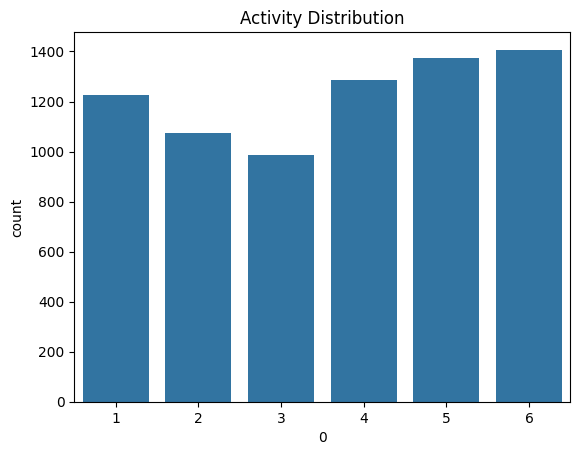

In [9]:
sns.countplot(x=y_train)
plt.title("Activity Distribution")
plt.show()

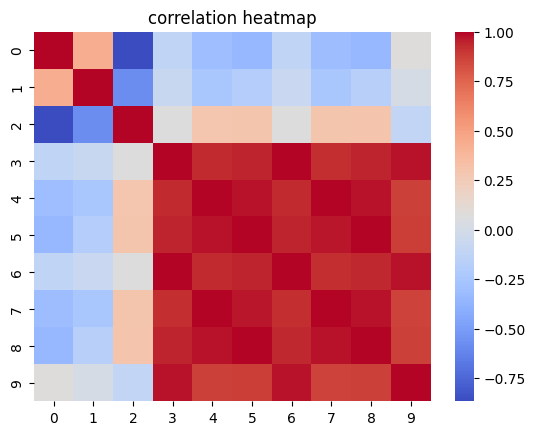

In [10]:
sns.heatmap(X_train.iloc[:100,:10].corr(),cmap="coolwarm")
plt.title("correlation heatmap")
plt.show()

In [12]:
rf = RandomForestClassifier(n_estimators=50,random_state=42)
rf.fit(X_train,y_train)
pred = rf.predict(X_test)
print(accuracy_score(y_test,pred))

0.9243298269426535


In [13]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.fit_transform(X_test)
svm = SVC()
svm.fit(X_train_s,y_train)
pred = svm.predict(X_test_s)
accuracy_score(y_test,pred)

0.9565659993213438

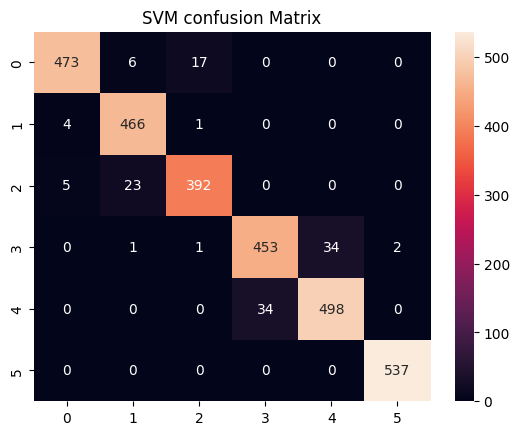

In [14]:
sns.heatmap(confusion_matrix(y_test,pred),annot=True,fmt="d")
plt.title("SVM confusion Matrix")
plt.show()

In [15]:
print("Random Forest:", rf.score(X_test, y_test))
print("SVM:", svm.score(X_test_s, y_test))

Random Forest: 0.9243298269426535
SVM: 0.9565659993213438
